# 小鼠与猕猴：参考末图基因、共同刻度与表达聚类

只展示 `mouse` 和 `macaque`，不展示大鼠。基因名单固定为 `6_VTA_DA_species_DEGs.ipynb` 最后一张已保存图中的 **70 个基因**（其 `plot_gene_map` 最终筛选结果），不再使用原 DEG 选基因表，也不重新筛选基因或进行差异检验。名单直接保存在下面的单元中，不依赖另一个 notebook 的内核运行状态。

输入使用现有 `three_species_processed.rds`，读取后立即筛选小鼠和猕猴，保留其全部细胞及已有 cluster 标签。该对象的 RNA counts 已统一为大写共同基因；不会重新聚类、整合或改变原始 RDS。

绘图时直接读取现有 `RNA/data` 层，将两物种表达合并为一张表，再用一次 `facet_grid` 绘图：每行一个基因，每列一个物种，各列展示本物种全部簇，**同一个基因在两物种间共享完全相同的表达量纵轴**，不同基因可使用不同纵轴。保留零表达；不重新运行 `NormalizeData`，不使用 counts、integrated 或 scale.data 代替绘图表达。

基因行按两物种各簇的平均 `RNA/data` 表达模式进行层次聚类：对每个基因的均值谱做行标准化，再使用欧氏距离、average linkage；常数谱放在末尾。标准化只决定行顺序，小提琴仍展示 `RNA/data` 原值。每行纵轴只保留最大刻度；上限取合并表达最大值向上取整（至少为 1）。

选择 **mb4.5.2** R 内核按单元运行。参数、合并后的 `plot_obj`、`gene_mean_expression`、`gene_clustering`、`plot_data`、`gene_scale`、`violin_plot` 均可直接查看；图和核对表写入独立目录。

In [ ]:
#%% 参数与依赖
suppressPackageStartupMessages({
  library(Seurat)
  library(Matrix)
  library(ggplot2)
})
root <- '/mnt/90-connectome/Personal/CQW/midbrain'
processed_path <- file.path(root, 'analysis/three_species_DA_20261109/three_species_processed.rds')
out <- file.path(root, 'analysis/mouse_macaque_shared_scale_20261110')
species_order <- c('mouse', 'macaque')
species_labels <- c(mouse = 'Mouse', macaque = 'Macaque')
species_colors <- c(mouse = '#8AB16D', macaque = '#DD806B')
plot_font <- 'sans'
violin_width <- 12
gene_row_height <- 0.30
dir.create(out, recursive = TRUE, showWarnings = FALSE)

In [ ]:
#%% 仅保留小鼠与猕猴，合并对象中保留原来的 cluster 标签
processed <- readRDS(processed_path)
stopifnot(all(c('species', 'cluster') %in% names(processed[[]])))
plot_cells <- colnames(processed)[processed$species %in% species_order]
plot_obj <- subset(processed, cells = plot_cells)
rm(processed)
invisible(gc())
DefaultAssay(plot_obj) <- 'RNA'
plot_obj@misc$species_comparison <- NULL
plot_obj$species <- factor(as.character(plot_obj$species), levels = species_order)
stopifnot(setequal(as.character(unique(plot_obj$species)), species_order),
          !anyNA(plot_obj$cluster), all(nzchar(as.character(plot_obj$cluster))))
print(table(plot_obj$species, plot_obj$cluster))

In [ ]:
#%% 参考 6_VTA_DA_species_DEGs.ipynb 最后一张已保存图的完整 70 个基因
# 按保存图中的行标签记录；只统一为当前 RNA 对象的大写符号，不新增或删选基因。
reference_notebook <- '/home/chaiqw/project/mb/Script/6_VTA_DA_species_DEGs.ipynb'
reference_genes <- c(
  'Tacr3', 'Gch1', 'Pitx3', 'Kcnd3', 'Th', 'Sv2c', 'Ddc', 'Slc6a3', 'Drd2',
  'Aldh2', 'Qdpr', 'Pink1', 'Comt', 'Maob', 'Arhgap10', 'Ift57', 'Ccdc112',
  'Slc18a2', 'Nr4a2', 'Man2a1', 'Kcnj6', 'Lmx1b', 'Kcnn3', 'Kcnh7', 'Slit3',
  'Aldh1a1', 'Sox6', 'Igf1', 'Arpp21', 'En1', 'Brinp3', 'Htr2c', 'Nfib',
  'Calb1', 'Lmx1a', 'Calb2', 'Myo1b', 'Nell1', 'Rps23', 'Ubb', 'Glra2',
  'Cbln4', 'Slc17a6', 'Onecut1', 'Moxd1', 'Tgfbr2', 'Cybrd1', 'Wnt7b',
  'Fam83b', 'Vip', 'Neurod6', 'Grp', 'Fau', 'Lepr', 'Cdc14a', 'Otx2', 'Cped1',
  'Calcr', 'Sncg', 'Cbln1', 'Cnbd1', 'Foxa2', 'Slc29a4', 'Mbnl3', 'Crhbp',
  'Cck', 'Gipr', 'Lpl', 'Lypd1', 'Gad2')
requested_genes <- toupper(reference_genes)
stopifnot(length(requested_genes) > 0L, !anyNA(requested_genes), all(nzchar(requested_genes)))
gene_presence <- data.frame(gene = requested_genes,
  present = requested_genes %in% rownames(plot_obj[['RNA']]))
missing_genes <- gene_presence$gene[!gene_presence$present]
stopifnot(length(requested_genes) == 70L, !anyDuplicated(requested_genes))
if (length(missing_genes)) stop('共同基因对象缺少参考图中的基因：', paste(missing_genes, collapse = ', '))
gene_order <- requested_genes
gene_labels <- setNames(reference_genes, requested_genes)
cat('参考末图基因数：', length(requested_genes), '\n')

In [ ]:
#%% 直接读取现有 RNA/data；不重新归一化，不读取 scale.data
stopifnot('data' %in% Layers(plot_obj[['RNA']]))
expression <- as.matrix(LayerData(plot_obj, assay = 'RNA', layer = 'data')[gene_order, , drop = FALSE])
plot_meta <- plot_obj[[]][colnames(expression), , drop = FALSE]
cluster_levels <- unique(as.character(plot_meta$cluster))
cluster_numbers <- as.integer(gsub('[^0-9]', '', cluster_levels))
stopifnot(!anyNA(cluster_numbers))
cluster_levels <- cluster_levels[order(cluster_numbers, cluster_levels)]

In [ ]:
#%% 按两物种各簇的平均表达模式对基因行聚类；细胞数量不决定簇的权重
cluster_ids <- paste(plot_meta$species, plot_meta$cluster, sep = '|')
cluster_ids_order <- unlist(lapply(species_order, function(sp) {
  paste(sp, cluster_levels[cluster_levels %in% plot_meta$cluster[plot_meta$species == sp]], sep = '|')
}), use.names = FALSE)
gene_mean_expression <- vapply(cluster_ids_order, function(id) {
  rowMeans(expression[, cluster_ids == id, drop = FALSE])
}, numeric(length(gene_order)))
rownames(gene_mean_expression) <- gene_order
gene_profile_sd <- apply(gene_mean_expression, 1, sd)
variable_genes <- names(gene_profile_sd)[gene_profile_sd > sqrt(.Machine$double.eps)]
constant_genes <- setdiff(gene_order, variable_genes)
gene_clustering <- NULL
clustered_genes <- variable_genes
if (length(variable_genes) >= 2L) {
  gene_scaled_expression <- t(scale(t(gene_mean_expression[variable_genes, , drop = FALSE])))
  gene_clustering <- hclust(dist(gene_scaled_expression), method = 'average')
  clustered_genes <- gene_clustering$labels[gene_clustering$order]
}
gene_order <- c(clustered_genes, constant_genes)
stopifnot(setequal(gene_order, requested_genes), !anyDuplicated(gene_order))
expression <- expression[gene_order, , drop = FALSE]
gene_mean_expression <- gene_mean_expression[gene_order, , drop = FALSE]

In [ ]:
#%% 按聚类后的行顺序合并绘图表，两个物种共用每个基因的表达量刻度
plot_data <- data.frame(
  gene = factor(rep(gene_order, ncol(expression)), levels = gene_order),
  cell = rep(colnames(expression), each = length(gene_order)),
  species = factor(rep(plot_meta$species, each = length(gene_order)), levels = species_order),
  cluster = factor(rep(plot_meta$cluster, each = length(gene_order)), levels = cluster_levels),
  expression = as.vector(expression))
stopifnot(!anyNA(plot_data), all(is.finite(plot_data$expression)),
          all(plot_data$expression >= 0),
          setequal(as.character(unique(plot_data$species)), species_order))
# 每个基因的展示范围取两物种合并后的范围，供核对共享刻度。
gene_scale <- data.frame(gene = gene_order, minimum = 0,
  expression_maximum = apply(expression, 1, max),
  axis_maximum = pmax(ceiling(apply(expression, 1, max)), 1), row.names = NULL)

In [ ]:
#%% 常数表达组用短横线表示，其余组绘制小提琴；不删除零表达细胞
groups <- split(seq_len(nrow(plot_data)),
  interaction(plot_data$gene, plot_data$species, plot_data$cluster, drop = TRUE))
variable <- vapply(groups, function(rows) length(rows) >= 2L &&
  any(plot_data$expression[rows] != plot_data$expression[rows[1]]), logical(1))
density_rows <- unlist(groups[variable], use.names = FALSE)
constant_rows <- vapply(groups[!variable], function(rows) rows[1], integer(1))

In [ ]:
groups <- split(
  seq_len(nrow(plot_data)),
  interaction(plot_data$gene, plot_data$species, plot_data$cluster, drop = TRUE)
)

variable <- vapply(groups, function(i) {
  length(i) >= 2L && length(unique(plot_data$expression[i])) > 1L
}, logical(1))

density_rows <- unlist(groups[variable], use.names = FALSE)
constant_rows <- vapply(groups[!variable], function(i) i[1], integer(1))

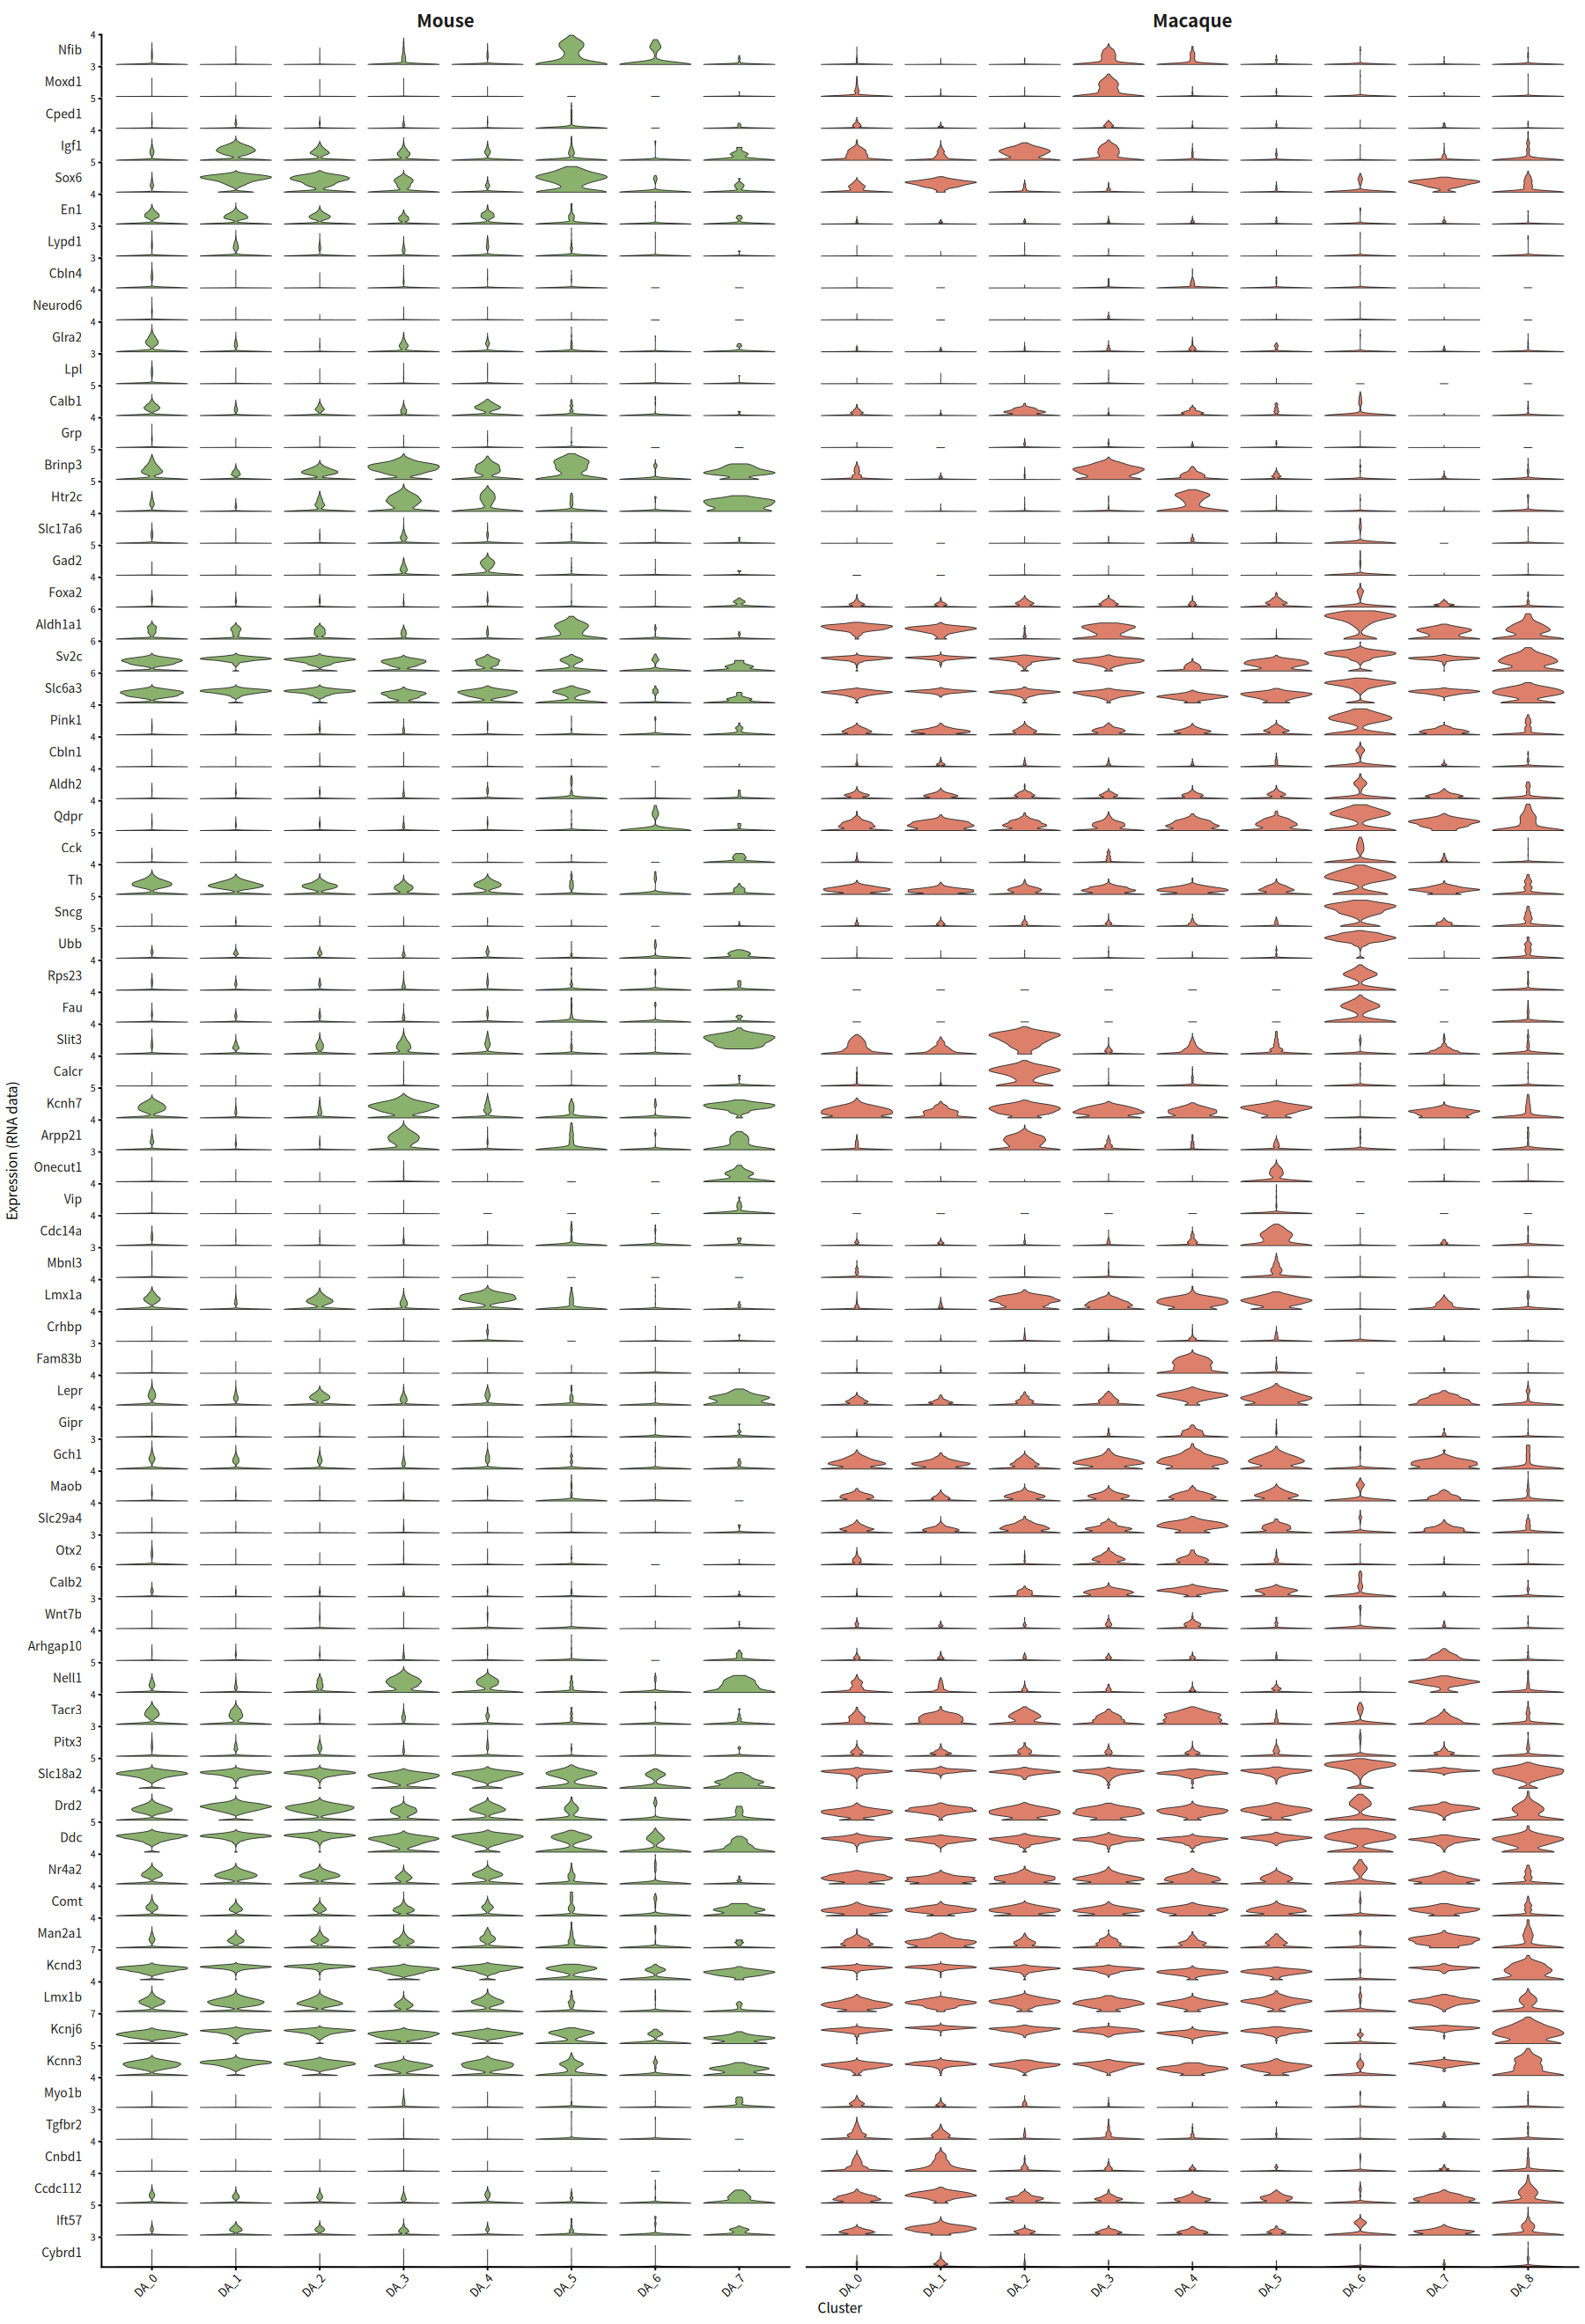

In [15]:
#%% 一次绘图：facet_grid 的同行面板共用 y 轴，按物种列分别保留各自的簇
violin_plot <- ggplot(plot_data, aes(cluster, expression, fill = species)) +
  geom_violin(data = plot_data[density_rows, , drop = FALSE],
    scale = 'width', trim = TRUE, linewidth = 0.2, width = 0.85) +
  geom_point(data = plot_data[constant_rows, , drop = FALSE], shape = 95, size = 3) +
  facet_grid(rows = vars(gene), cols = vars(species), scales = 'free',
    space = 'free_x', switch = 'y',
    labeller = labeller(species = species_labels, gene = gene_labels)) +
  scale_fill_manual(values = species_colors, breaks = species_order, drop = TRUE) +
  scale_y_continuous(limits = function(z) c(0, max(ceiling(z[2]), 1)),
    breaks = function(z) max(z), minor_breaks = NULL, expand = expansion(mult = c(0, 0))) +
  labs(x = 'Cluster', y = 'Expression (RNA data)') +
  theme_classic(base_size = 9, base_family = plot_font) +
  theme(legend.position = 'none', strip.background = element_blank(),
    strip.placement = 'outside', strip.text.x = element_text(face = 'bold', size = 12),
    strip.text.y.left = element_text(angle = 0, hjust = 1, size = 8),
    panel.spacing.x = grid::unit(0.8, 'lines'), panel.spacing.y = grid::unit(0.1, 'lines'),
    axis.text.x = element_text(angle = 45, hjust = 1), axis.text.y = element_text(size = 6))
violin_height <- max(3, length(gene_order) * gene_row_height + 1)
options(repr.plot.width = 15, repr.plot.height = violin_height)
print(violin_plot)

In [ ]:
#%% 保存图及核对信息；原来的 DEG 结果、RDS 和其他 notebook 不变
ggsave(file.path(out, 'mouse_macaque_shared_scale_violin.pdf'), violin_plot,
  width = violin_width, height = violin_height, units = 'in',
  device = grDevices::cairo_pdf, family = plot_font, limitsize = FALSE)
ggsave(file.path(out, 'mouse_macaque_shared_scale_violin.png'), violin_plot,
  width = violin_width, height = violin_height, units = 'in', dpi = 180,
  bg = 'white', limitsize = FALSE)
write.csv(gene_presence, file.path(out, 'original_gene_presence.csv'), row.names = FALSE)
write.csv(gene_scale, file.path(out, 'shared_gene_expression_ranges.csv'), row.names = FALSE)
write.csv(data.frame(row_order = seq_along(gene_order), gene = gene_order,
  label = unname(gene_labels[gene_order])), file.path(out, 'clustered_gene_order.csv'), row.names = FALSE)
write.csv(gene_mean_expression, file.path(out, 'gene_cluster_mean_expression.csv'), row.names = TRUE)
saveRDS(gene_clustering, file.path(out, 'gene_row_clustering.rds'))
cell_counts <- as.data.frame(table(species = plot_meta$species, cluster = plot_meta$cluster))
cell_counts <- cell_counts[cell_counts$Freq > 0, ]
write.csv(cell_counts, file.path(out, 'species_cluster_cell_counts.csv'), row.names = FALSE)
cat('结果已保存至：', out, '\n')